In [113]:
from langgraph.graph import StateGraph,START,END
import cohere
from langchain_cohere import ChatCohere
from dotenv import load_dotenv
import os
from typing import TypedDict,Annotated
import operator
from pydantic import BaseModel, Field

In [114]:
load_dotenv()

True

In [115]:
model_name = "command-a-plus-05-2026"

In [116]:
model=ChatCohere(model=model_name)

In [117]:
class EvaluationSchema(BaseModel):
    feedback: str = Field(description="Detailed feedback for the essay")
    score: int = Field(description="Score out of 10, an integer from 0 to 10")


In [118]:
structured_model= model.with_structured_output(EvaluationSchema)

In [119]:
essay = """India in the Age of AI
As the world enters a transformative era defined by artificial intelligence (AI), India stands at a critical juncture — one where it can either emerge as a global leader in AI innovation or risk falling behind in the technology race. The age of AI brings with it immense promise as well as unprecedented challenges, and how India navigates this landscape will shape its socio-economic and geopolitical future.

India's strengths in the AI domain are rooted in its vast pool of skilled engineers, a thriving IT industry, and a growing startup ecosystem. With over 5 million STEM graduates annually and a burgeoning base of AI researchers, India possesses the intellectual capital required to build cutting-edge AI systems. Institutions like IITs, IIITs, and IISc have begun fostering AI research, while private players such as TCS, Infosys, and Wipro are integrating AI into their global services. In 2020, the government launched the National AI Strategy (AI for All) with a focus on inclusive growth, aiming to leverage AI in healthcare, agriculture, education, and smart mobility.

One of the most promising applications of AI in India lies in agriculture, where predictive analytics can guide farmers on optimal sowing times, weather forecasts, and pest control. In healthcare, AI-powered diagnostics can help address India’s doctor-patient ratio crisis, particularly in rural areas. Educational platforms are increasingly using AI to personalize learning paths, while smart governance tools are helping improve public service delivery and fraud detection.

However, the path to AI-led growth is riddled with challenges. Chief among them is the digital divide. While metropolitan cities may embrace AI-driven solutions, rural India continues to struggle with basic internet access and digital literacy. The risk of job displacement due to automation also looms large, especially for low-skilled workers. Without effective skilling and re-skilling programs, AI could exacerbate existing socio-economic inequalities.

Another pressing concern is data privacy and ethics. As AI systems rely heavily on vast datasets, ensuring that personal data is used transparently and responsibly becomes vital. India is still shaping its data protection laws, and in the absence of a strong regulatory framework, AI systems may risk misuse or bias.

To harness AI responsibly, India must adopt a multi-stakeholder approach involving the government, academia, industry, and civil society. Policies should promote open datasets, encourage responsible innovation, and ensure ethical AI practices. There is also a need for international collaboration, particularly with countries leading in AI research, to gain strategic advantage and ensure interoperability in global systems.

India’s demographic dividend, when paired with responsible AI adoption, can unlock massive economic growth, improve governance, and uplift marginalized communities. But this vision will only materialize if AI is seen not merely as a tool for automation, but as an enabler of human-centered development.
In conclusion, India’s journey in the age of AI is at a crossroads. By leveraging its strengths, addressing its challenges, and fostering an inclusive and ethical AI ecosystem, India can position itself as a global leader in the AI revolution. The choices made today will determine whether India thrives in this new era or becomes a passive observer of technological change.
"""

In [120]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
structured_model.invoke(prompt)

EvaluationSchema(feedback='The essay is well‑structured and coherent, with a compelling introduction that frames India’s AI opportunity and a logical progression through strengths, applications, challenges, and recommendations. It effectively integrates data (e.g., 5\u202fmillion STEM graduates) and concrete examples, which strengthens its argument. The language is generally clear and academic, and the conclusion ties the main points together neatly. To raise the language quality further, consider varying sentence length to avoid occasional repetition, tighten some transitional phrases, and refine the final paragraph to reinforce the central thesis more forcefully. Minor grammatical polishing (e.g., consistent use of “AI‑driven” vs. “AI driven”) would also improve fluency. Overall, the essay demonstrates strong language quality with room for fine‑tuning.', score=9)

In [121]:
print(structured_model)

first=_ChatModelBinding(bound=ChatCohere(client=<cohere.client.Client object at 0x13140d850>, async_client=<cohere.client.AsyncClient object at 0x13140c1d0>, model='command-a-plus-05-2026', cohere_api_key=SecretStr('**********'), metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6'}}), kwargs={'response_format': {'type': 'json_object', 'schema': {'properties': {'feedback': {'description': 'Detailed feedback for the essay', 'title': 'Feedback', 'type': 'string'}, 'score': {'description': 'Score out of 10, an integer from 0 to 10', 'title': 'Score', 'type': 'integer'}}, 'required': ['feedback', 'score'], 'title': 'EvaluationSchema', 'type': 'object'}}}, config={}, config_factories=[]) middle=[] last=PydanticOutputParser(pydantic_object=<class '__main__.EvaluationSchema'>)


In [122]:
class state(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int],operator.add]
    avg_score: float


In [123]:
def get_language_feedback(state: state) -> dict:
    prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    result = structured_model.invoke(prompt)
    return {
        "language_feedback": result.feedback,
        "individual_scores": [result.score],
    }

In [124]:
def get_analysis_feedback(state: state) -> dict:
    prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    result = structured_model.invoke(prompt)
    return {
        "analysis_feedback": result.feedback,
        "individual_scores": [result.score],
    }

In [125]:
def get_clarity_feedback(state: state) -> dict:
    prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    result = structured_model.invoke(prompt)
    return {
        "clarity_feedback": result.feedback,
        "individual_scores": [result.score],
    }

In [126]:
def get_overall_feedback(state:state)->dict:
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'
    result= structured_model.invoke(prompt)
    avg_score=sum(state["individual_scores"])/len(state["individual_scores"])
    return {
        "overall_feedback":result.feedback,
        "avg_score":avg_score

    }

In [127]:
graph=StateGraph(state)
graph.add_node("get_language_feedback",get_language_feedback)
graph.add_node("get_analysis_feedback",get_analysis_feedback)
graph.add_node("get_clarity_feedback",get_clarity_feedback)
graph.add_node("get_overall_feedback",get_overall_feedback)
graph.add_edge(START,"get_language_feedback")
graph.add_edge(START,"get_analysis_feedback")
graph.add_edge(START,"get_clarity_feedback")

graph.add_edge("get_language_feedback","get_overall_feedback")
graph.add_edge("get_analysis_feedback","get_overall_feedback")
graph.add_edge("get_clarity_feedback","get_overall_feedback")
graph.add_edge("get_overall_feedback",END)
workflow=graph.compile()

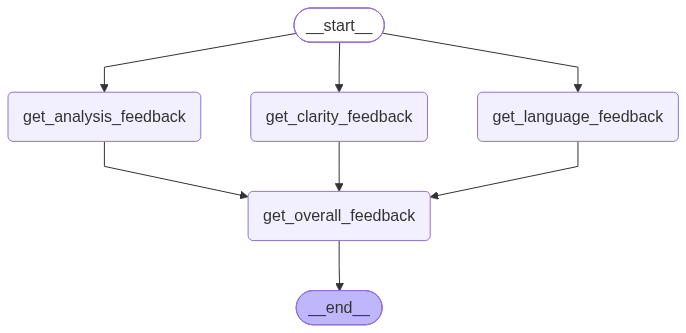

In [128]:
workflow

In [129]:
initial_state={"essay":essay}
final_state=workflow.invoke(initial_state)
print(final_state)

{'essay': "India in the Age of AI\nAs the world enters a transformative era defined by artificial intelligence (AI), India stands at a critical juncture — one where it can either emerge as a global leader in AI innovation or risk falling behind in the technology race. The age of AI brings with it immense promise as well as unprecedented challenges, and how India navigates this landscape will shape its socio-economic and geopolitical future.\n\nIndia's strengths in the AI domain are rooted in its vast pool of skilled engineers, a thriving IT industry, and a growing startup ecosystem. With over 5 million STEM graduates annually and a burgeoning base of AI researchers, India possesses the intellectual capital required to build cutting-edge AI systems. Institutions like IITs, IIITs, and IISc have begun fostering AI research, while private players such as TCS, Infosys, and Wipro are integrating AI into their global services. In 2020, the government launched the National AI Strategy (AI for 

In [130]:
print(final_state['individual_scores'])
print(final_state['avg_score'])

[7, 9, 9]
8.333333333333334


In [131]:
essay2 = """Ai in india

Ai is very good thing and india have many peoples so ai is going to be big. Everyone is use ai now a days like phone and computer and also in the office. I think ai is good because it is good for everything and many peoples like it.

In india there is many engineers and they makes ai. Some company is big and they does ai also. Government also do ai things but I don't know what exactly. Ai can help farmers and hospital and school and many other thing. Its very helpful and it will be helping a lot.

But ai also have problem. Some peoples will lose job because machine do work, but also new jobs will come but maybe not. Also data is a problem and internet is a problem in village. But I think these problem is not big problem, or maybe it is big, I am not sure.

In the end ai is good and bad both and india should use ai but also not use too much. If india use ai then india will be good country. That is all I want to say about ai in india."""


In [132]:
initial_state2={"essay":essay2}
final_state2=workflow.invoke(initial_state2)
print(final_state2)

{'essay': "Ai in india\n\nAi is very good thing and india have many peoples so ai is going to be big. Everyone is use ai now a days like phone and computer and also in the office. I think ai is good because it is good for everything and many peoples like it.\n\nIn india there is many engineers and they makes ai. Some company is big and they does ai also. Government also do ai things but I don't know what exactly. Ai can help farmers and hospital and school and many other thing. Its very helpful and it will be helping a lot.\n\nBut ai also have problem. Some peoples will lose job because machine do work, but also new jobs will come but maybe not. Also data is a problem and internet is a problem in village. But I think these problem is not big problem, or maybe it is big, I am not sure.\n\nIn the end ai is good and bad both and india should use ai but also not use too much. If india use ai then india will be good country. That is all I want to say about ai in india.", 'language_feedback'

In [133]:
print(final_state2['individual_scores'])
print(final_state2['avg_score'])

[3, 4, 4]
3.6666666666666665


In [134]:
final_state

{'essay': "India in the Age of AI\nAs the world enters a transformative era defined by artificial intelligence (AI), India stands at a critical juncture — one where it can either emerge as a global leader in AI innovation or risk falling behind in the technology race. The age of AI brings with it immense promise as well as unprecedented challenges, and how India navigates this landscape will shape its socio-economic and geopolitical future.\n\nIndia's strengths in the AI domain are rooted in its vast pool of skilled engineers, a thriving IT industry, and a growing startup ecosystem. With over 5 million STEM graduates annually and a burgeoning base of AI researchers, India possesses the intellectual capital required to build cutting-edge AI systems. Institutions like IITs, IIITs, and IISc have begun fostering AI research, while private players such as TCS, Infosys, and Wipro are integrating AI into their global services. In 2020, the government launched the National AI Strategy (AI for 